# 05. ODD+LLM Provenance, Physics Clamping & Tamper Audit

- **Goal:** Inspect real LLM Block C provenance (Ollama version, model digest SHA, `seed`), host physics clamping, and tamper detection.
- **Case & Window:** F.E. Walter `dkp` offline mocked-Ollama LLM audit (`21` daily steps, `2021-01-01`–`2021-01-21`).
- **Pass Criterion:** Clean run `PASS` with `odd_llm_manifest.json`; 1-byte tamper -> `verify_run FAIL`.

*Runs 100% offline via mocked Ollama endpoints (`0` real network calls).*

In [1]:
import tempfile
from pathlib import Path
import sys
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for p in (Path.cwd(), *Path.cwd().parents):
    if (p / "tutorials" / "_helpers.py").is_file():
        sys.path.insert(0, str(p))
        break
from tutorials import _helpers as h

REPO_ROOT = h.find_repo_root()
C = h.configure_plots()

## 1. Run Verified LLM Audit Demo & Inspect Blocks A–E

`run_settings` automatically writes `odd_llm_manifest.json` (plus `export_odd_report`) capturing Blocks A–E and runtime model snapshots.

In [2]:
with tempfile.TemporaryDirectory() as td:
    audit = h.run_offline_llm_audit_demo(REPO_ROOT, Path(td))

verification = audit["verification"]
manifest = audit["manifest"]
odd_markdown = audit["odd_markdown"]
tamper_caught = audit["tamper_caught"]
tamper_error = audit["tamper_error"]

b = manifest["blocks"]
ag_b = b["B_identity"]["FEWalter"]
ag_c = b["C_inference_configuration"]["agents"]["FEWalter"]
snap = ag_c["server_runtime_snapshot"]["primary"]
res_d = b["D_behavioral_submodel"]["resolution"]
blk_e = b["E_validation"]

rows = [
    ("Block A (Cognitive)", "Strategy, DKP SHA, physical bounds", f"dkp | {b['A_cognitive_architecture']['FEWalter']['long_term_knowledge']['package_ids']}"),
    ("Block B (Identity)", "Prompt ID, version & SHA-256", f"{ag_b['prompt_id']} v{ag_b['prompt_version']} ({str(ag_b['prompt_sha256'])[:12]}...)"),
    ("Block C (Inference)", "Ollama version, weights SHA, seed, deps", f"Ollama {snap['server_version']} | {snap['requested_model']} {snap['quantization_level']} | {snap['model_digest_sha256'][:19]}... | seed={ag_c['seed']}"),
    ("Block D (Submodel)", "Clipping & audit resolution telemetry", f"clip_steps={res_d['physical_clipping_steps']} | audits={res_d['audit_counts']}"),
    ("Block E (Validation)", "Mass residual & SHA-pinned artifacts", f"{verification['status']} | residual={blk_e['max_mass_balance_residual_m3']:.2e} m3 | files={len(blk_e['output_files_sha256'])}"),
]
print(pd.DataFrame(rows, columns=["ODD+LLM Block", "What It Pins", "Observed Value"]).to_string(index=False))


       ODD+LLM Block                            What It Pins                                                      Observed Value
 Block A (Cognitive)      Strategy, DKP SHA, physical bounds                                                    dkp | ['dkp.md']
  Block B (Identity)            Prompt ID, version & SHA-256                                         None v3.7 (e9febc2dfcee...)
 Block C (Inference) Ollama version, weights SHA, seed, deps Ollama 0.40.6 | gemma4:12b Q4_K_M | sha256:1278394b6936... | seed=3
  Block D (Submodel)   Clipping & audit resolution telemetry                       clip_steps=3 | audits={'FAIL': 3, 'PASS': 18}
Block E (Validation)    Mass residual & SHA-pinned artifacts                               PASS | residual=8.20e-11 m3 | files=5


## 2. Visualize Volume Closure & Host Clamping

Confirm full-network closure (including `channel_storage_end_m3`) and inspect Day 5 where host physics clamped an aggressive LLM release.

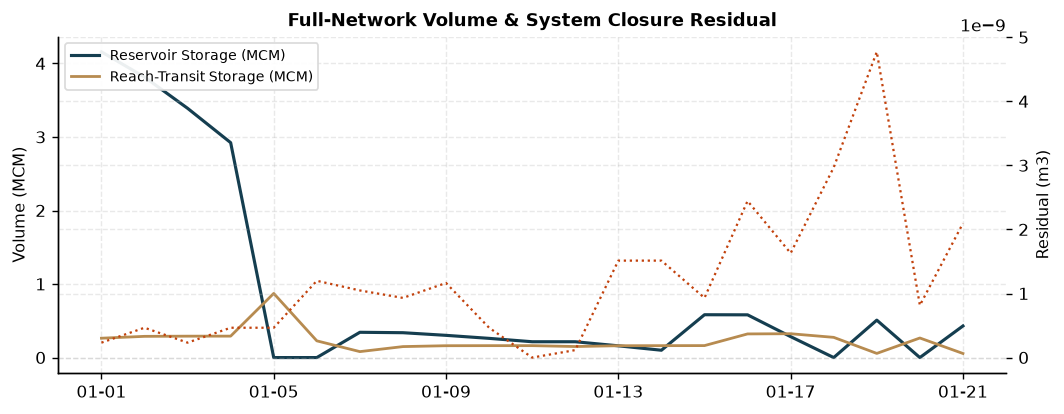

In [3]:
nb = audit["network_balance"]
traj = audit["trajectory"]
dates = pd.to_datetime(traj["date"].astype(str).str.slice(0, 10))

fig, ax1 = plt.subplots(figsize=(8.6, 3.4))
ax1.plot(dates, traj["storage_end_m3"] / 1e6, color=C["navy"], lw=1.8, label="Reservoir Storage (MCM)")
ax1.plot(dates, nb["channel_storage_end_m3"] / 1e6, color=C["gold"], lw=1.6, label="Reach-Transit Storage (MCM)")
ax1_r = ax1.twinx()
ax1_r.plot(dates, nb["system_residual_m3"].abs(), color=C["coral"], ls=":", lw=1.3, label="|System Residual| (m3)")
ax1_r.spines["top"].set_visible(False); ax1.set_title("Full-Network Volume & System Closure Residual")
ax1.set_ylabel("Volume (MCM)"); ax1_r.set_ylabel("Residual (m3)")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d")); ax1.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

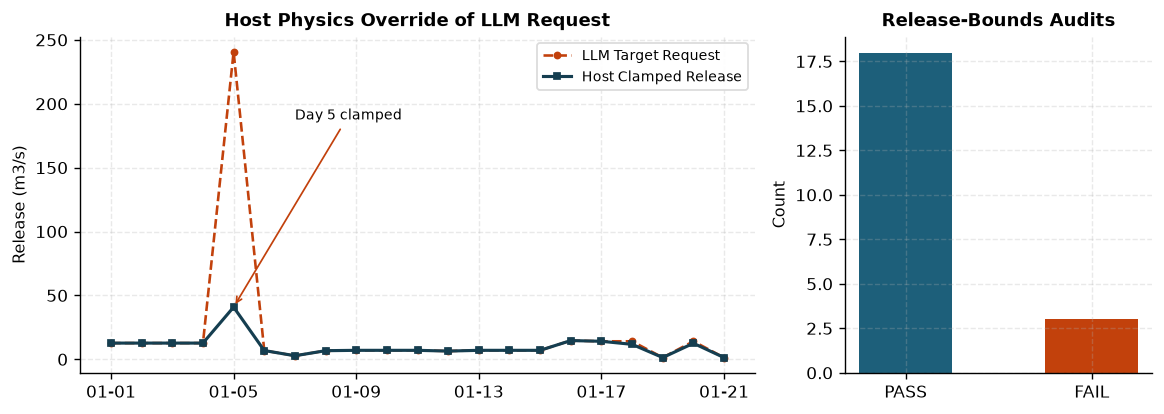

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.4, 3.4), gridspec_kw={"width_ratios": [2.2, 1.0]})
ax1.plot(dates, traj["target_release_cms"], color=C["coral"], ls="--", marker="o", ms=3.5, label="LLM Target Request")
ax1.plot(dates, traj["controlled_release_cms"], color=C["navy"], lw=1.8, marker="s", ms=3.2, label="Host Clamped Release")
idx_clip = int(np.argmax(traj["target_release_cms"] - traj["controlled_release_cms"]))
ax1.annotate("Day 5 clamped", xy=(dates.iloc[idx_clip], traj["controlled_release_cms"].iloc[idx_clip]),
             xytext=(dates.iloc[idx_clip + 2], traj["target_release_cms"].iloc[idx_clip] * 0.78),
             arrowprops=dict(arrowstyle="->", color=C["coral"]), fontsize=8)
ax1.set_title("Host Physics Override of LLM Request"); ax1.set_ylabel("Release (m3/s)")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d")); ax1.legend(loc="upper right", fontsize=8)

labels, vals = list(audit["audit_counts"].keys()), list(audit["audit_counts"].values())
ax2.bar(labels, vals, color=[C["teal"] if k == "PASS" else C["coral"] for k in labels], width=0.5)
ax2.set_title("Release-Bounds Audits"); ax2.set_ylabel("Count")
plt.tight_layout(); plt.show()

## 3. Prove 1-Byte Tamper Detection (`verify_run` -> `FAIL`)

Editing even 1 byte in a saved output file breaks its SHA-256 manifest digest and is rejected offline.

In [5]:
print(f"Original run verdict : {verification['status']}")
print(f"1-byte tamper caught : {tamper_caught}")
print(f"Tamper rejection msg : {tamper_error}")
print("\n--- Exported ODD+LLM Markdown Preview (first 8 lines) ---")
for line in odd_markdown.splitlines()[:8]:
    print(" ", line)

Original run verdict : PASS
1-byte tamper caught : True
Tamper rejection msg : ValueError: output hash mismatch: reservoir_trajectory.csv

--- Exported ODD+LLM Markdown Preview (first 8 lines) ---
  # ODD+LLM Reproducibility Report: `tutorial-m05-dkp-audit-demo`
  
  - **Protocol**: ODD+LLM (CoALA-grounded ABM extension)
  - **Schema Version**: `odd-llm-reproducibility.v1`
  - **Time Axis**: `daily` · `dt = 86400 s` · `2021-01-01` to `2021-01-21` (`21` steps)
  
  ## Agents Summary
  


- **Model + seed snapshot:** Block C pins Ollama version, weights SHA-256, quantization, `seed`, and Python dependencies.
- **Physical sovereignty:** Host physics clamps aggressive withdrawals while logging every adjustment.

## 4. Package Your Peer-Review Bundle

- **Zero-GPU replay:** Archive `archived_releases.csv` for offline reviewer verification (`0` model calls).
- **Verify:** `reservoir-experiment verify <run_dir> --require-offline`
- **Export:** `reservoir-experiment export-odd <run_dir> --markdown-out ODD_LLM.md`

Back to: [Tutorial Hub](../README.md)